# Exercice 5 : Entraîner avec la confidentialité différentielle (DP-SGD)

> **Objectif.** Entraîner le modèle de prédiabète de l'exercice 4 avec DP-SGD (écrêtage + bruit), d'abord à la main sur un lot, puis avec Opacus.
> Tracer la courbe **précision vs ε** et vérifier que l'attaque d'appartenance retombe à pile ou face.

**Volets du plan de cours (séance 12) :** *mécanismes formels de confidentialité* (confidentialité différentielle, DP-SGD) appliqués à la *prévention des fuites d'information* de l'exercice 4.

**Rappel de la définition.** Un algorithme est (ε, δ)-différentiellement privé si, pour deux jeux de données qui ne diffèrent que d'**un** patient, la probabilité de tout résultat change au plus d'un facteur e^ε (plus une petite probabilité δ d'échec).
Autrement dit : que votre dossier soit dedans ou non, le modèle obtenu est presque le même. ε petit = forte protection. Règle d'usage : δ bien plus petit que 1/n (ici δ = 10⁻⁵ pour n = 1 000).

**DP-SGD (Abadi *et al.*, CCS 2016)** modifie une seule étape de la descente de gradient :
1. calculer le gradient **de chaque patient** séparément ;
2. **écrêter** chacun à une norme maximale C (aucun patient ne pèse plus que C) ;
3. additionner et ajouter un **bruit gaussien** d'écart-type σ·C ;
4. faire le pas habituel (SGD ou Adam).

Un **comptable** (*accountant*) additionne la perte de vie privée de chaque pas et donne l'ε final.

**Dépendances :** `torch`, `opacus` (Meta, licence Apache 2.0), `scikit-learn`, `matplotlib` (installés par l'étape 0).

**Les données.** Les mêmes qu'à l'exercice 4 : patients adultes Synthea « 10K COVID-19 » (Apache 2.0, synthétiques), cible prédiabète, 1 000 membres et 1 000 non-membres.

**Le plan.**
1. Point de départ : le modèle sur-appris de l'exercice 4.
2. DP-SGD à la main, sur un lot.
3. DP-SGD avec Opacus, pour un ε.
4. La courbe précision vs ε.
5. Le levier oublié : plus de données.

## Étape 0 : exécutez cette cellule en premier
Elle installe les paquets manquants et, sur Colab, récupère `helper.py` et `data/` depuis GitHub. Elle doit afficher **Prêt : True**.

In [1]:
# Dépendances de ce notebook : torch opacus scikit-learn matplotlib
import os, sys, importlib.util
if not os.path.exists('helper.py'):   # notebook ouvert depuis Google Drive / Colab
    !test -d /content/cours || git clone -q --depth 1 https://github.com/elyesmanai/8IAR805---Cybersecurity-AI.git /content/cours
    %cd "/content/cours/Chapitre 7 - IA et vie privée"
manquants = [pip for module, pip in {'torch': 'torch', 'opacus': 'opacus', 'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib'}.items() if importlib.util.find_spec(module) is None]
if manquants:
    %pip install -q {' '.join(manquants)}
print('Prêt :', os.path.exists('helper.py') and os.path.exists('data'))

Prêt : True


## Étape 1 : Le point de départ
**Ce qu'on fait :** on refait le modèle sur-appris de l'exercice 4 (même découpage, même graine) pour avoir la référence sans protection.

In [2]:
import torch, numpy as np, pandas as pd
torch.set_num_threads(4)
from helper import dossiers_medicaux, decoupage, creer_mlp, entrainer, precision_test, attaque_appartenance

X, y, _ = dossiers_medicaux()
membres, non_membres, test = decoupage(len(X), n_train=1000)

sans_dp = entrainer(creer_mlp(X.shape[1]), X[membres], y[membres], epoques=150)
reference = {'précision test': precision_test(sans_dp, X[test], y[test]), **attaque_appartenance(sans_dp, X, y, membres, non_membres)}
reference

{'précision test': 0.8569353667392883, 'AUC': 0.639, 'avantage': 0.289}

## Étape 2 : DP-SGD à la main, sur un seul lot
**Ce qu'on fait :** on regarde les 4 étapes sur un lot de 64 patients. `torch.func` calcule les 64 gradients individuels en une seule passe.

In [3]:
from torch.func import functional_call, vmap, grad
import torch.nn.functional as F

modele = creer_mlp(X.shape[1])
params = {k: v.detach() for k, v in modele.named_parameters()}
xb, yb = torch.tensor(X[membres[:64]]), torch.tensor(y[membres[:64]]).long()

def perte_un_patient(p, x, cible):
    return F.cross_entropy(functional_call(modele, p, (x.unsqueeze(0),)), cible.unsqueeze(0))

# 1. un gradient PAR patient
g = vmap(grad(perte_un_patient), in_dims=(None, 0, 0))(params, xb, yb)
normes = torch.sqrt(sum((gi.flatten(1) ** 2).sum(1) for gi in g.values()))

# 2. écrêtage à C
C, sigma = 1.0, 1.0
facteur = torch.clamp(C / normes, max=1.0)
g_ecrete = {k: v * facteur.view(-1, *[1] * (v.dim() - 1)) for k, v in g.items()}

# 3. somme + bruit gaussien N(0, (sigma*C)^2), puis moyenne
g_prive = {k: (v.sum(0) + torch.randn_like(v[0]) * sigma * C) / len(xb) for k, v in g_ecrete.items()}

print(f'Normes des gradients individuels : min {normes.min():.2f}, médiane {normes.median():.2f}, max {normes.max():.2f}')
print(f'Après écrêtage : max {(normes * facteur).max():.2f}  (= C)')
print(f'Écart-type du bruit ajouté à la somme : {sigma * C}')

Normes des gradients individuels : min 1.09, médiane 1.42, max 1.92
Après écrêtage : max 1.00  (= C)
Écart-type du bruit ajouté à la somme : 1.0


**👀 Ce qu'on doit voir :** certains patients ont un gradient bien plus fort que d'autres ; après écrêtage, **aucun** ne dépasse C. Le bruit, calibré sur C, masque alors la contribution de n'importe quel patient individuel.
C'est tout DP-SGD. Le difficile, c'est le **comptage** de ε sur des milliers de pas : on le confie à Opacus.

## Étape 3 : Opacus, pour ε = 2
**Ce qu'on fait :** on demande à Opacus un budget ε = 2 (δ = 10⁻⁵) pour 20 époques. Il calcule lui-même le multiplicateur de bruit σ nécessaire, puis entraîne le **même réseau** qu'à l'exercice 4.

In [4]:
from helper import entrainer_dp
modele_dp, sigma = entrainer_dp(X[membres], y[membres], epsilon=2.0)
print(f'Multiplicateur de bruit choisi par Opacus : sigma = {sigma:.2f}')
{'précision test': precision_test(modele_dp, X[test], y[test]), **attaque_appartenance(modele_dp, X, y, membres, non_membres)}

Multiplicateur de bruit choisi par Opacus : sigma = 3.60


{'précision test': 0.8468893730331639, 'AUC': 0.497, 'avantage': 0.024}

**👀 Ce qu'on doit voir :** une précision proche (voire meilleure) que le modèle sur-appris, et une AUC d'attaque ≈ 0,5. Le bruit et l'écrêtage agissent aussi comme une régularisation.

## Étape 4 : La courbe précision vs ε
**Ce qu'on fait :** on entraîne un modèle par budget, de très protecteur (ε = 0,5) à peu protecteur (ε = 8). Environ une minute en tout sur CPU.

In [5]:
import time
lignes = []
for eps in [8, 4, 2, 1, 0.5]:
    debut = time.time()
    m, s = entrainer_dp(X[membres], y[membres], epsilon=eps)
    lignes.append({'epsilon': eps, 'sigma': round(s, 2), 'précision test': precision_test(m, X[test], y[test]),
                   **attaque_appartenance(m, X, y, membres, non_membres), 'durée (s)': round(time.time() - debut, 1)})
courbe = pd.DataFrame(lignes)
courbe.round(3)

,epsilon,sigma,précision test,AUC,avantage,durée (s)
0,8.0,1.29,0.866,0.520,0.045,19.0
1,4.0,2.07,0.860,0.509,0.036,18.5
2,2.0,3.60,0.847,0.497,0.024,17.4
3,1.0,6.60,0.817,0.490,0.018,17.8
4,0.5,12.50,0.779,0.489,0.020,17.9


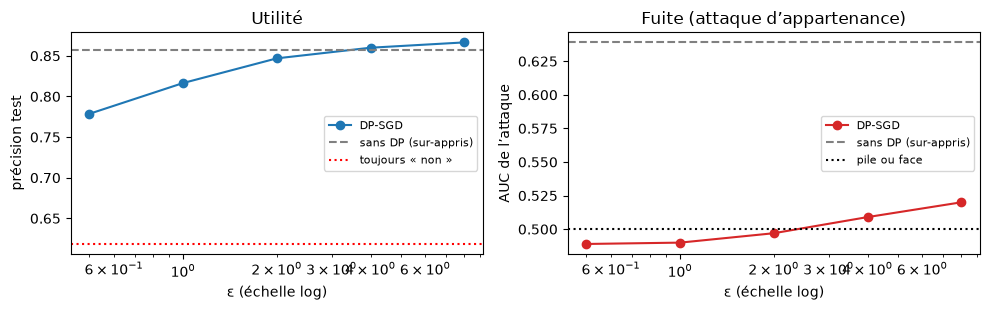

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(courbe['epsilon'], courbe['précision test'], 'o-', label='DP-SGD')
ax[0].axhline(reference['précision test'], color='gray', ls='--', label='sans DP (sur-appris)')
ax[0].axhline(1 - y[test].mean(), color='red', ls=':', label='toujours « non »')
ax[0].set(xscale='log', xlabel='ε (échelle log)', ylabel='précision test', title='Utilité'); ax[0].legend(fontsize=8)
ax[1].plot(courbe['epsilon'], courbe['AUC'], 'o-', color='C3', label='DP-SGD')
ax[1].axhline(reference['AUC'], color='gray', ls='--', label='sans DP (sur-appris)')
ax[1].axhline(0.5, color='black', ls=':', label='pile ou face')
ax[1].set(xscale='log', xlabel='ε (échelle log)', ylabel='AUC de l’attaque', title='Fuite (attaque d’appartenance)'); ax[1].legend(fontsize=8)
plt.tight_layout()

**👀 Ce qu'on doit voir :**
- **À gauche**, la précision reste au niveau du modèle sans DP pour ε entre 2 et 8, puis baisse quand ε descend sous 1 (σ explose : le bruit noie le signal de 1 000 patients).
- **À droite**, l'AUC de l'attaque est collée à 0,5 pour **tous** les ε testés, alors qu'elle valait environ 0,65 sans DP.

Attention à la lecture : une AUC à 0,5 pour *notre* attaque ne « prouve » rien en soi ; la garantie vient de la **définition** (ε borne ce que **n'importe quelle** attaque peut apprendre). L'expérience confirme simplement que la garantie se voit en pratique.

## Étape 5 : Le levier oublié, plus de données
**Ce qu'on fait :** à budget égal (ε = 0,5), on entraîne sur 5 000 patients au lieu de 1 000. Le bruit est calibré pour masquer **un** patient : plus il y a de patients, plus le signal collectif domine le bruit.
Pour comparer à armes égales, on garde la **même proportion de patients par lot** (128 / 1 000 = 12,8 %), donc des lots de 640 : le bruit, ajouté une fois par lot, se divise alors par un lot 5 fois plus grand.

In [7]:
grands_membres, _, grand_test = decoupage(len(X), n_train=5000)
m5000, s5000 = entrainer_dp(X[grands_membres], y[grands_membres], epsilon=0.5, batch=640)   # même taux d'échantillonnage : 640 / 5 000 = 128 / 1 000
print(f'ε = 0,5 avec 1 000 patients : précision {courbe.set_index("epsilon").loc[0.5, "précision test"]:.3f}')
print(f'ε = 0,5 avec 5 000 patients : précision {precision_test(m5000, X[grand_test], y[grand_test]):.3f}  (sigma = {s5000:.2f})')

ε = 0,5 avec 1 000 patients : précision 0.779
ε = 0,5 avec 5 000 patients : précision 0.866  (sigma = 12.50)


**👀 Ce qu'on doit voir :** avec 5 fois plus de patients, ε = 0,5 redonne une précision proche de celle du modèle sans protection (≈ 0,87 contre ≈ 0,78 avec 1 000 patients).
Attention : avec des lots de 128, on ne gagnerait rien. Avec la DP, la taille du lot est un vrai réglage (de grands lots diluent le bruit), pas un détail. C'est pourquoi la DP est déployée là où les données sont massives (par exemple le recensement américain de 2020), et peine sur les petites cohortes.

## Ce qu'il faut retenir
- La confidentialité différentielle est une **garantie** sur l'algorithme, pas sur une attaque : ε borne l'influence d'**un** individu sur le résultat.
- **DP-SGD** = gradient par exemple + **écrêtage** à C + **bruit** gaussien σ·C + comptable de ε. Opacus fait tout cela en 3 lignes (`make_private_with_epsilon`).
- Le coût en précision dépend de ε **et** de la taille du jeu : faible à ε ≈ 2-8, fort sous ε = 1 avec 1 000 patients, presque nul avec 5 000.
- L'attaque d'appartenance de l'exercice 4 retombe à pile ou face. Dans un cadre **fédéré** (FedAvg), DP-SGD côté client protège aussi contre la fuite par les gradients partagés.

**Exercice suivant :** l'apprentissage **décentralisé** (fédéré) entre 14 hôpitaux, ce que ses gradients révèlent, et DP-SGD dans chaque hôpital.